In [1]:
import warnings

import paulssonlab.deaton.trenchripper.trenchripper as tr

warnings.filterwarnings(action="once")

import matplotlib

matplotlib.rcParams["figure.figsize"] = [20, 10]

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
# addition of active memory manager
import dask

dask.config.set({"distributed.scheduler.active-memory-manager.start": True})
dask.config.set({"distributed.scheduler.worker-ttl": "5m"})
dask.config.set({"distributed.scheduler.allowed-failures": 100})

dask_wd = "/home/lag36/scratch/lag36/dask"

In [3]:
headpath = "/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/Barcodes/"
hdf5inputpath = "/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/run_10-cycles/"

In [19]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=20, #100,
    n_workers_min=20,
    memory="2GB",#"8GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

50m
1:00:00


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/node.py:168: ResourceWarning: unclosed <socket.socket fd=88, family=AddressFamily.AF_INET, type=SocketKind.SOCK_STREAM, proto=6, laddr=('0.0.0.0', 0)>
  if retries_left < 1:
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/node.py:182: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 34271 instead
  warnings.warn(


In [20]:
hdf5_extractor = tr.marlin_extractor(
    hdf5inputpath,
    headpath,
    pixel_microns=0.105951961895293*2,
    metaparsestr="metadata_{timepoint:d}.hdf5",
)

In [21]:
# Get the attributes of the hdf5_extractor
hdf5_extractor.__dict__

{'hdf5inputpath': '/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/run_10-cycles/',
 'headpath': '/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/Barcodes/',
 'metapath': '/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/Barcodes//metadata.hdf5',
 'hdf5path': '/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/Barcodes//hdf5',
 'tempregpath': '/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/Barcodes//registration_temp',
 'tpts_per_file': 100,
 'parsestr': 'fov={fov:d}_config={channel}_t={timepoints:d}.hdf5',
 'metaparsestr': 'metadata_{timepoint:d}.hdf5',
 'zero_base_keys': ['timepoints'],
 'register_images': False,
 'reg_channel': None,
 'pixel_microns': 0.211903923790586,
 'organism': '',
 'microscope': '',
 'notes': '',
 'channel_to_flat_dict': {}}

## Check kymographs manually

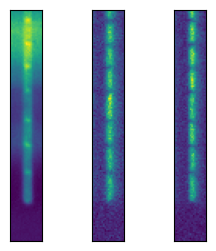

In [4]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
outer_ind = '4'
channels = ["BF", "mCherry-Penta", "GFP-Penta"]
trench_index = 118 # BAD: 1 (k30), GOOD: k30-20
with h5py.File(
    "/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/Growth_Division/kymograph/kymograph_processed_10.hdf5",
    "r",
) as infile:
    fig, axs = plt.subplots(nrows=1, ncols = 3, figsize=(3, 3))  
    for i, ch in enumerate(channels):
        axs[i].imshow(infile[outer_ind][ch][trench_index][0]) # 0 bc only 1 timepoint
        for ax in axs:
            ax.axes.get_xaxis().set_ticks([])
            ax.axes.get_yaxis().set_ticks([])

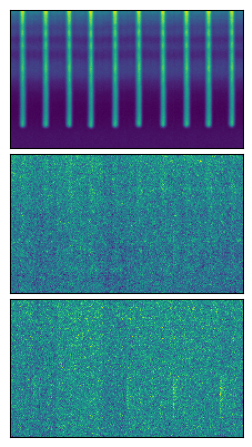

In [27]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
outer_ind = '4'
channels = ["BF", "RFP", "Cy5"]
trench_index = 20#50 # BAD: 1 (k30), GOOD: k30-20
indices = list(range(0, 10, 1))
with h5py.File(
    "/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/Barcodes/kymograph/kymograph_processed_10.hdf5",
    "r",
) as infile:
    fig, axs = plt.subplots(nrows=3, ncols = 1, figsize=(3, 10)) 
    # Bring axes close together
    fig.subplots_adjust(hspace=-0.7, wspace=0.1) 
    for i, ch in enumerate(channels):
        img = infile[outer_ind][ch][trench_index][indices[0]][25:,:]

        for ind in indices[1:]:
            img_ind = infile[outer_ind][ch][trench_index][ind][25:,:]
            img = np.concatenate((img, img_ind), axis=1)
        axs[i].imshow(img) # 0 bc only 1 timepoint
        for ax in axs:
            ax.axes.get_xaxis().set_ticks([])
            ax.axes.get_yaxis().set_ticks([])

In [ ]:
import h5py
import matplotlib.pyplot as plt
import numpy as np

channels = ["BF", "GFP", "Cy5", "Cy7"]
trench_index = 6  # BAD: 1 (k30), GOOD: k30-20
with h5py.File(
    "/home/lag36/scratch/lag36/2023-05-06_lDE30_Run_1/Barcodes/kymograph/kymograph_2.hdf5",
    "r",
) as infile:
    indices = list(range(0, 10, 1))

    for ch in channels:
        img = infile[ch][trench_index][indices[0]]
        for ind in indices:
            img_ind = infile[ch][trench_index][ind]
            img = np.concatenate((img, img_ind), axis=1)
        plt.figure(figsize=(3, 6))
        plt.imshow(img, cmap="gray", aspect=0.5)
        plt.show()
        plt.close()